# Unit 6 — companion notebook
Code for the worked examples in the [Unit 6 notes](https://elevien.github.io/math50_sandbox/unit6/).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist

rng = np.random.default_rng(0)

### Example: Laplace's rule of succession

In [2]:
N, Y = 10, 10  # all successes
a_prior, b_prior = 1, 1  # uniform prior = Beta(1,1)
posterior_mean = (Y + a_prior) / (N + a_prior + b_prior)
laplace = (Y + 1) / (N + 2)
print("posterior mean:", posterior_mean, " Laplace's rule:", laplace)

posterior mean: 0.9166666666666666  Laplace's rule: 0.9166666666666666


### Example: selecting priors

In [3]:
z, half_width = 1.96, 0.1
var_target = (half_width / z) ** 2
a = 1 / (8 * var_target) - 0.5  # from var(Beta(a,a)) = 1/(4(2a+1))
print("a ~", a)

N, Y = 5, 5
posterior_mean = (Y + a) / (N + 2 * a)
print("posterior mean with informative prior:", posterior_mean)
print("posterior mean with uniform prior (Laplace):", (Y + 1) / (N + 2))

# check against scipy
print("scipy Beta(Y+a, N-Y+a) mean:", beta_dist(Y + a, N - Y + a).mean())

a ~ 47.519999999999996
posterior mean with informative prior: 0.5249900039984007
posterior mean with uniform prior (Laplace): 0.8571428571428571
scipy Beta(Y+a, N-Y+a) mean: 0.5249900039984007


### Example: computing the posterior mean in Python

In [4]:
N = 200
beta_true = np.array([1.5, -0.8])
sigma = 1.0
X1, X2 = rng.normal(size=N), rng.normal(size=N)
A = np.column_stack([X1, X2])
Y = A @ beta_true + rng.normal(scale=sigma, size=N)

for tau in [0.1, 1, 10, 100]:
    Lambda0_inv = np.eye(2) / tau**2
    M = A.T @ A + sigma**2 * Lambda0_inv
    beta_bar = np.linalg.solve(M, A.T @ Y)
    print(f"tau={tau}: beta_bar = {beta_bar}")

tau=0.1: beta_bar = [ 1.02682421 -0.52616874]
tau=1: beta_bar = [ 1.55897898 -0.73827998]
tau=10: beta_bar = [ 1.56712093 -0.74122843]
tau=100: beta_bar = [ 1.56720278 -0.74125803]


### Example: posterior predictions for a Fourier regression model

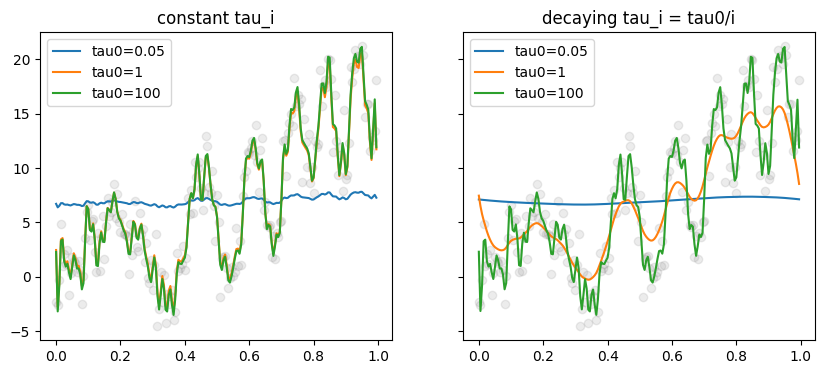

In [5]:
N, K, L = 200, 50, 1.0
X = np.arange(N) / N
f_true = lambda x: np.sin(2*np.pi*3*x) + 5*np.sin(2*np.pi*6*x**2) + 20*x**2
sigma = 2.0
Y = f_true(X) + rng.normal(scale=sigma, size=N)

def design(X, K, L):
    cols = [np.ones_like(X)]
    for i in range(1, K + 1):
        cols.append(np.sin(2 * np.pi * i * X / L))
        cols.append(np.cos(2 * np.pi * i * X / L))
    return np.column_stack(cols)

A = design(X, K, L)

def fit_ridge(tau_vec):
    Lambda0_inv = np.diag(1 / tau_vec**2)
    M = A.T @ A + sigma**2 * Lambda0_inv
    return np.linalg.solve(M, A.T @ Y)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for tau0 in [0.05, 1, 100]:
    tau_const = np.full(A.shape[1], tau0); tau_const[0] = 1e6  # unpenalized intercept
    axes[0].plot(X, A @ fit_ridge(tau_const), label=f"tau0={tau0}")

    idx = np.repeat(np.arange(1, K + 1), 2)
    tau_decay = np.concatenate([[1e6], tau0 / idx])
    axes[1].plot(X, A @ fit_ridge(tau_decay), label=f"tau0={tau0}")

for ax, title in zip(axes, ["constant tau_i", "decaying tau_i = tau0/i"]):
    ax.scatter(X, Y, alpha=0.15, color="gray")
    ax.set_title(title)
    ax.legend()
plt.show()

### Example: orthogonal empirical covariance matrix (kernel trick)

In [6]:
N, K, L = 100, 20, 1.0
X = np.arange(N) / N
phis = [np.sin(2*np.pi*i*X/L) for i in range(1, K+1)] + [np.cos(2*np.pi*i*X/L) for i in range(1, K+1)]
phis = [p / np.sqrt(np.sum(p**2)) for p in phis]  # rescale so sum phi_i(X_k)^2 = 1
A = np.column_stack(phis)

Omega = A.T @ A
print("max off-diagonal |Omega_ij|:", np.max(np.abs(Omega - np.eye(len(phis)))))

sigma, tau = 1.0, 2.0
Y = np.sin(2 * np.pi * 3 * X) + rng.normal(scale=0.3, size=N)
beta_bar = (A.T @ Y) / (1 + (sigma / tau) ** 2)

x0 = 0.37
a0 = np.array(
    [np.sin(2*np.pi*i*x0/L) / np.sqrt(np.sum(np.sin(2*np.pi*i*X/L)**2)) for i in range(1, K+1)] +
    [np.cos(2*np.pi*i*x0/L) / np.sqrt(np.sum(np.cos(2*np.pi*i*X/L)**2)) for i in range(1, K+1)]
)
yhat_direct = a0 @ beta_bar

# kernel form: yhat = sum_j Y_j * kappa(x0, X_j)
kernel_weights = (a0[None, :] * A).sum(axis=1) / (1 + (sigma / tau) ** 2)
yhat_kernel = np.sum(kernel_weights * Y)

print("direct posterior-mean prediction:", yhat_direct)
print("via kernel form:                 ", yhat_kernel)

max off-diagonal |Omega_ij|: 1.810559863199e-15
direct posterior-mean prediction: 0.47232082074093207
via kernel form:                  0.472320820740932
